# Introduction to Classification

In [1]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [2]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


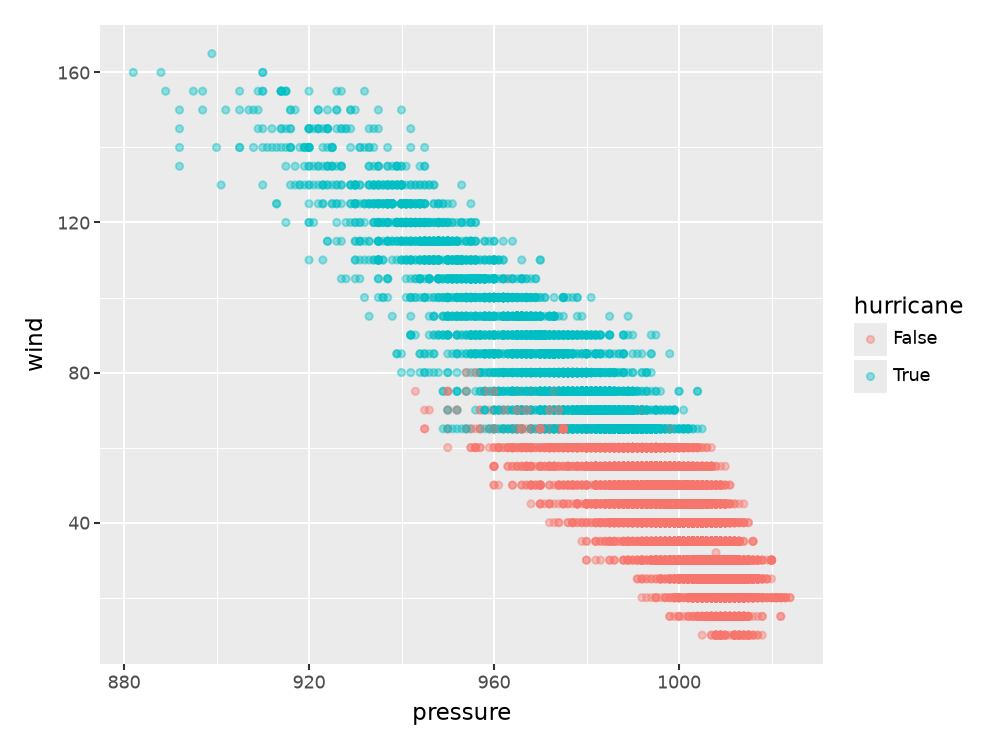

In [3]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

Predict hurricane if wind speed is at least 65 knots; otherwise predict non-hurricane. The hurricane points are at or above this wind speed, while most non-hurricane points are below it, so this should give high precision and recall.

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

In [4]:
pred_hurricane = df_storms["wind"] >= 65
actual_hurricane = df_storms["hurricane"]

tp = (pred_hurricane & actual_hurricane).sum()
fp = (pred_hurricane & ~actual_hurricane).sum()
fn = (~pred_hurricane & actual_hurricane).sum()
tn = (~pred_hurricane & ~actual_hurricane).sum()

accuracy = (tp + tn) / len(df_storms)
precision_hurricane = tp / (tp + fp)
recall_hurricane = tp / (tp + fn)
f1_hurricane = 2 * tp / (2 * tp + fp + fn)
precision_non_hurricane = tn / (tn + fn)
recall_non_hurricane = tn / (tn + fp)
f1_non_hurricane = 2 * tn / (2 * tn + fn + fp)

print(f"a. Training accuracy: {accuracy:.2%} of storm observations are classified correctly.")
print(f"b. Hurricane precision: {precision_hurricane:.2%} of observations predicted to be hurricanes are actually hurricanes.")
print(f"c. Hurricane recall: {recall_hurricane:.2%} of actual hurricane observations are predicted to be hurricanes.")
print(f"d. Hurricane F1: {f1_hurricane:.2%}, the harmonic mean of hurricane precision and recall.")
print(f"e. Non-hurricane precision: {precision_non_hurricane:.2%} of observations predicted to be non-hurricanes are actually non-hurricanes.")
print(f"f. Non-hurricane recall: {recall_non_hurricane:.2%} of actual non-hurricane observations are predicted to be non-hurricanes.")
print(f"g. Non-hurricane F1: {f1_non_hurricane:.2%}, the harmonic mean of non-hurricane precision and recall.")

a. Training accuracy: 99.33% of storm observations are classified correctly.
b. Hurricane precision: 97.34% of observations predicted to be hurricanes are actually hurricanes.
c. Hurricane recall: 100.00% of actual hurricane observations are predicted to be hurricanes.
d. Hurricane F1: 98.65%, the harmonic mean of hurricane precision and recall.
e. Non-hurricane precision: 100.00% of observations predicted to be non-hurricanes are actually non-hurricanes.
f. Non-hurricane recall: 99.11% of actual non-hurricane observations are predicted to be non-hurricanes.
g. Non-hurricane F1: 99.55%, the harmonic mean of non-hurricane precision and recall.


Part f repeats precision; I interpreted it as recall. F1 combines precision and recall into one score; it is not the percentage of observations classified correctly.

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

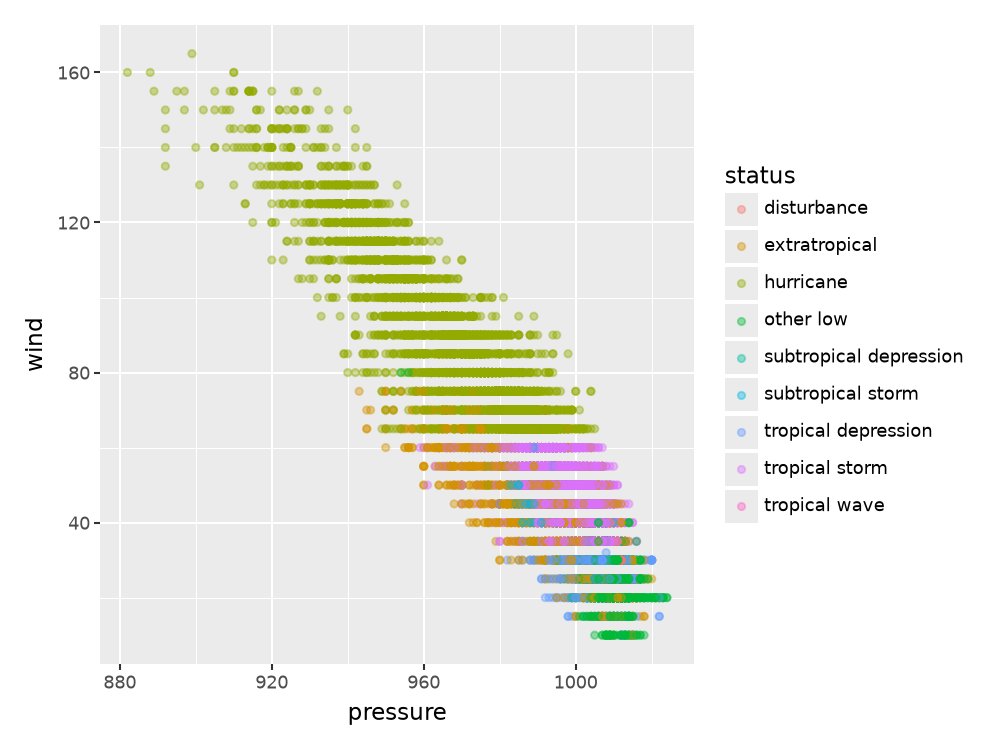

In [5]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

I would expect extratropical. The closest points to pressure 975 and wind speed 39 appear to be mostly extratropical. The prediction uses the most common status among the 10 nearest observations, including observations that overlap on the plot, so the visible dots do not show all of the neighbors.

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

I would expect disturbance, tropical wave, subtropical depression, and subtropical storm to have the lowest recall. These classes appear less common and overlap with more common classes. Their observations are likely to have neighbors from other classes, so the model may miss many of their actual observations. Overlapping points make the exact recalls hard to judge from the plot alone.

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [6]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

X = df_titanic[["age", "gender", "class"]]
y = df_titanic["survived"]

preprocessor = ColumnTransformer([
    ("standardize", StandardScaler(), ["age"]),
    ("encode", OneHotEncoder(), ["gender", "class"])
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['age','gender','class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('encode', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [8]:
passengers = pd.DataFrame({
    "age": [20, 20],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

predictions = model.predict(passengers)
probabilities = model.predict_proba(passengers)

for i in range(2):
    outcome = "survive" if predictions[i] == 1 else "not survive"
    print(f"A 20-year-old female in {passengers.loc[i, 'class']} class is predicted to {outcome}.")
    print(f"Predicted probability of survival: {probabilities[i, 1]:.1%}; non-survival: {probabilities[i, 0]:.1%}.")

A 20-year-old female in 1st class is predicted to survive.
Predicted probability of survival: 100.0%; non-survival: 0.0%.
A 20-year-old female in 3rd class is predicted to not survive.
Predicted probability of survival: 20.0%; non-survival: 80.0%.


3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_pred = model.predict(X)

precision_survived = precision_score(y, y_pred)
recall_survived = recall_score(y, y_pred)
f1_survived = f1_score(y, y_pred)

print(f"Precision: {precision_survived:.2%} of passengers predicted to survive actually survived.")
print(f"Recall: {recall_survived:.2%} of passengers who actually survived are predicted to survive.")
print(f"F1: {f1_survived:.2%}, the harmonic mean of survivor precision and recall.")

Precision: 84.50% of passengers predicted to survive actually survived.
Recall: 54.43% of passengers who actually survived are predicted to survive.
F1: 66.21%, the harmonic mean of survivor precision and recall.


4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [10]:
precision_died = precision_score(y, y_pred, pos_label=0)
recall_died = recall_score(y, y_pred, pos_label=0)
f1_died = f1_score(y, y_pred, pos_label=0)

print(f"Precision: {precision_died:.2%} of passengers predicted not to survive actually did not survive.")
print(f"Recall: {recall_died:.2%} of passengers who actually did not survive are predicted not to survive.")
print(f"F1: {f1_died:.2%}, the harmonic mean of non-survivor precision and recall.")

Precision: 81.45% of passengers predicted not to survive actually did not survive.
Recall: 95.25% of passengers who actually did not survive are predicted not to survive.
F1: 87.81%, the harmonic mean of non-survivor precision and recall.


5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [11]:
survival_probability = model.predict_proba(X)[:, 1]
y_pred_05 = (survival_probability >= 0.5).astype(int)
y_pred_08 = (survival_probability >= 0.8).astype(int)

for label, name in [(1, "survivors"), (0, "non-survivors")]:
    precision_05 = precision_score(y, y_pred_05, pos_label=label)
    recall_05 = recall_score(y, y_pred_05, pos_label=label)
    precision_08 = precision_score(y, y_pred_08, pos_label=label)
    recall_08 = recall_score(y, y_pred_08, pos_label=label)
    print(f"For {name}, precision changes from {precision_05:.2%} to {precision_08:.2%}, and recall changes from {recall_05:.2%} to {recall_08:.2%}.")

For survivors, precision changes from 77.04% to 91.79%, and recall changes from 62.31% to 42.48%.
For non-survivors, precision changes from 83.56% to 78.20%, and recall changes from 91.16% to 98.19%.


Raising the survival threshold to 0.8 predicts fewer survivors. Survivor recall cannot increase, and non-survivor recall cannot decrease. Survivor precision often rises and non-survivor precision often falls; the calculated values above show the actual changes. This follows the question’s rule that a probability equal to the threshold predicts survival. With model.predict, a 0.5 tie instead predicts class 0.

6\. Plot the precision-recall curve for the survivors. Interpret what you see.

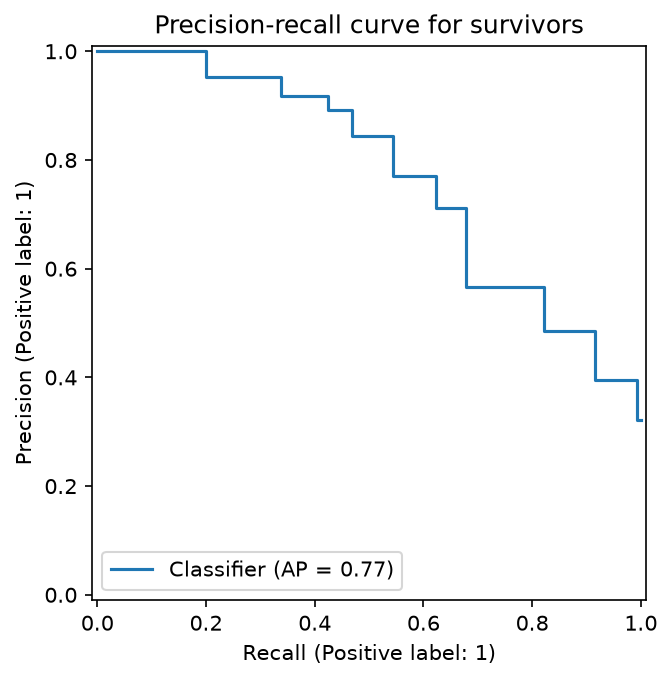

In [12]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(y, survival_probability, pos_label=1)
plt.title("Precision-recall curve for survivors")
plt.show()

Each point shows survivor precision and recall at a different probability threshold. A higher threshold predicts fewer survivors and reduces or maintains recall; a lower threshold finds more actual survivors but can include more non-survivors. Points closer to the upper-right corner give both high precision and high recall.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

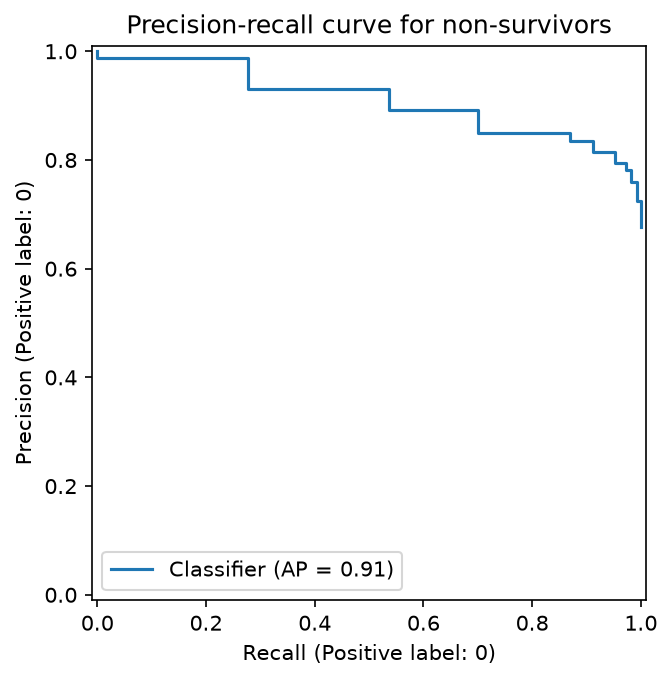

In [13]:
non_survival_probability = model.predict_proba(X)[:, 0]

PrecisionRecallDisplay.from_predictions(y, non_survival_probability, pos_label=0)
plt.title("Precision-recall curve for non-survivors")
plt.show()

Each point shows non-survivor precision and recall at a different threshold for the probability of non-survival. Lowering that threshold identifies more actual non-survivors but can also label survivors as non-survivors. Points closer to the upper-right corner give better precision and recall together.